# Notebook 03 — Crop and Align CWF Particles; Extract Radial, FFT, and Combined Features

**Overview:** This notebook prepares particle-level numerical features from Camille’s CWF images for downstream unsupervised analysis. It reads the full cropped CWF checkpoint generated in Notebook 02b, works with the original and derivative image channels, and aligns each particle using shared transformations so both channels remain paired. It then extracts spatial intensity descriptors from radial rings and angular sectors, computes Fourier (FFT) descriptors, and combines selected feature blocks into the final `combined_cropped` feature matrix used in Notebook 09.

**Particle ordering:** The CWF image and feature rows follow the original raw MRC stack order, **not** the STAR metadata row order. Saved particle identifiers and checkpoint checks preserve that correspondence; downstream validation must match frozen folds by particle identity rather than row number.

**Extracted from:** `expeirment.ipynb` (original cells 28–43).

**Prerequisites:** Reads existing CWF checkpoints. Run in order: setup, paired crops, preview, alignment, radial aggregation, FFT, then weighted combined features. Default input is `normalized_camille`; edit the controls for your saved data.

**Execution:** Use the same working directory / project layout as the original notebook. Required local Python modules under `LatentSpace/` and saved datasets under `outputs/` are **not included** in this archive. Outputs are removed from this split copy to reduce file size; all original code and Markdown within this section are preserved.

This notebook is extracted from: expeirment.ipynb (original cells 28–43). The original Markdown is kept in all sections.

# 3. Paired circle-cropped original and derivative features

## 3.1. Source and adjustable parameters

Use the same centered circle as before: radius = `seg_growth_radius_fraction × min(height, width)`. Keep every original pixel within it. `seg_preserve_edge_strength=False` makes selected derivative pixels binary (1); True retains their gradient magnitude. Compute the Gaussian derivative magnitude on the full image, threshold using its whole-image percentile, then clip it to that circle. No intensity mask, flood filling, component removal, or margin expansion is used.

All Section 3 controls are below. Rerun 3.2 onward after changing them. Cropping retains the original grid and sets pixels outside the circle to zero.


In [9]:
# Input and circle/derivative controls.
seg_input_source = "normalized_camille"  # own, camille, normalized_camille
seg_saved_directory = None
seg_image_count = None
seg_sigma = 1.0
seg_preserve_edge_strength = False  # False: binary edge map; True: retained gradient magnitudes.
seg_edge_percentile = 70.0  # Percentile of the WHOLE derivative image, per image.
seg_growth_radius_fraction = 0.35

# Alignment: major axis vertical; secondary lobe upper-right after reflections.
seg_alignment_secondary_exclusion = 15.0  # Exclude this cone around the main axis.
seg_alignment_secondary_sector = 20.0  # Angular half-width of the secondary lobe.
seg_alignment_min_axis_ratio = 1.1  # Below this: flag uncertain major axis.
seg_alignment_secondary_contrast = 0.05  # Below this: flag ambiguous mirror choice.

# Paired radial aggregation: n intensity sums + n strictly-positive pixel counts.
agg_method = "intensity_sum"
agg_n_sectors = 8
agg_n_radial_bands = 3  # Equal-width rings inside the existing crop circle.
agg_count_mode = "fraction"  # "fraction" = positive pixels / bin area; "count" = raw count.
agg_positive_threshold = 0.0  # On rotated binary edges, >0 includes interpolation support.
agg_start_angle_degrees = 45.0  # Clockwise from 12 o'clock; 0 starts at 12.
# No within-vector normalization; occupancy fractions account for unequal bin areas.
fft_remove_support_mean = True  # Subtract mean INSIDE the saved circle, then zero outside.
# No FFT taper is added. All other normalization and crop settings are unchanged.

# Previews and export.
seg_preview_count = 6
seg_export_dpi = 160


In [10]:
# ADDED: Verify that the original alignment settings are available.
# Reason: Avoid running alignment with undefined parameters.

print("Secondary exclusion:", seg_alignment_secondary_exclusion)
print("Secondary sector:", seg_alignment_secondary_sector)
print("Minimum axis ratio:", seg_alignment_min_axis_ratio)
print("Secondary contrast:", seg_alignment_secondary_contrast)

Secondary exclusion: 15.0
Secondary sector: 20.0
Minimum axis ratio: 1.1
Secondary contrast: 0.05


Each checkpoint preserves full image IDs. Derived checkpoints refer to their exact parent files, and Section 3.10 rejects aggregation/FFT checkpoints from different alignments. The original and derivative share identical saved transforms.

The old 3.4–3.6 mask-margin and multiple-rotation branch is retired here. Previously saved `rotated` and `rotated_average` datasets remain selectable downstream. Subsequent subsection numbers are retained.


In [3]:
from pathlib import Path
import sys
import importlib
import json
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project using the same relative-path setup as Notebooks 01 and 02b.
working_directory = Path.cwd().resolve()

project_root = next(
    (
        p for p in (working_directory, *working_directory.parents)
        if (p / "latent_methods.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find the ML4LS project root (latent_methods.py). "
        "Start Jupyter inside the repository or one of its subdirectories."
    )

# ADDED: Preserve the variable names used elsewhere in Notebook 03.
seg_project = project_root

if str(seg_project) not in sys.path:
    sys.path.insert(0, str(seg_project))
import importlib
import cwf_storage
importlib.reload(cwf_storage)
from cwf_storage import select_cwf_directory
import particle_aggregation
importlib.reload(particle_aggregation)
import particle_paired
importlib.reload(particle_paired)
from particle_paired import (PAIRED_SOURCES, crop_pairs, align_pairs, aggregate_pairs,
    fft_pairs, combine_pairs, load_paired_dataset, preview_pairs, loading_maps)
seg_root = seg_project / "outputs"


## 3.2. Clip and save both channels

Save `cropped_original` and `cropped_derivative`, their shared IDs, the circle mask, and each image's numeric derivative cutoff. The derivative output is **binary by default**; select `seg_preserve_edge_strength=True` to retain magnitudes. Zero-gradient pixels are always excluded. The saved settings record the choice.


In [2]:
# ADDED: Locate particle_paired.py in the project.
# Reason: Identify the correct import directory before loading
# the completed cropping checkpoint.

from pathlib import Path
import sys

# ORIGINAL: Use our established project directory.
project_root = seg_project  # MODIFIED: Use the detected project root.

# ADDED: Search for the module without loading any particle images.
matches = sorted(project_root.rglob("particle_paired.py"))

print("Found module files:")
for path in matches:
    print(path)

# ADDED: Add the containing directory to Python's search path.
if len(matches) == 1:
    module_directory = str(matches[0].parent)

    if module_directory not in sys.path:
        sys.path.insert(0, module_directory)

    # ADDED: Verify that importing the module now works.
    from particle_paired import load_paired_dataset

    print("\nImport successful!")
elif len(matches) == 0:
    print("\nModule not found. Do not run the cropping cell yet.")
else:
    print("\nMultiple module files found. We need to select the correct one.")

Found module files:
/Users/kr/ml4ls/particle_paired.py

Import successful!


In [4]:
# ORIGINAL: This cell loaded cwf_result.npz and called crop_pairs().
# MODIFIED: Reuse the full cropping checkpoint from Notebook 02b.
# Reason: All 57,107 CWF particles have already been cropped,
# so we should not process or save them a second time.

from pathlib import Path
from particle_paired import load_paired_dataset

# ADDED: Locate the verified cropping checkpoint.
crop_checkpoint = seg_project / "outputs" / "camille_cwf_full_crops"  # MODIFIED
# ADDED: Define the output directory explicitly.
# Reason: The original setup cell defining seg_root
# has not yet been executed in this Jupyter session.
seg_root = seg_project / "outputs"  # MODIFIED

# ADDED: Load the existing cropped images using memory mapping.
seg_cropped = load_paired_dataset(
    root=seg_root,
    source="cropped_original",
    directory=crop_checkpoint,
)

# ADDED: Verify the loaded dataset.
assert seg_cropped["images"].shape == (57107, 64, 64)
assert len(seg_cropped["image_names"]) == 57107

print("Cropping checkpoint loaded successfully!")
print("Checkpoint:", seg_cropped["directory"])
print("Image shape:", seg_cropped["images"].shape)
print("Particle IDs:", len(seg_cropped["image_names"]))
print("Empty derivative masks:", int(seg_cropped["empty_masks"].sum()))


Cropping checkpoint loaded successfully!
Checkpoint: /Users/kr/ml4ls/outputs/camille_cwf_full_crops
Image shape: (57107, 64, 64)
Particle IDs: 57107
Empty derivative masks: 0


In [13]:
# MODIFIED: Use the exact parameter names accepted by _alignment().
# ORIGINAL: Preserve the alignment settings from Notebook 03.
# ADDED: Test alignment estimation on only 32 particles.
# Memory-safe: Does not process the full dataset.

import numpy as np
import pandas as pd
import particle_paired

# ADDED: Open the existing derivative maps without loading
# all 57,107 images into RAM.
derivative_images = np.load(
    crop_checkpoint / "cropped_derivative.npy",
    mmap_mode="r",
)

# MODIFIED: Match the actual _alignment() function signature.
alignment_controls = {
    "exclusion": seg_alignment_secondary_exclusion,
    "sector": seg_alignment_secondary_sector,
    "min_axis_ratio": seg_alignment_min_axis_ratio,
    "min_contrast": seg_alignment_secondary_contrast,
}

# ADDED: Estimate alignment parameters for the first 32 particles.
test_records = [
    {
        "image_name": str(name),
        **particle_paired._alignment(
            image,
            **alignment_controls
        ),
    }
    for name, image in zip(
        seg_cropped["image_names"][:32],
        derivative_images[:32],
    )
]

# ADDED: Collect results in a table.
test_alignment = pd.DataFrame(test_records)

# ADDED: Verify that every test particle has an alignment record.
assert len(test_alignment) == 32
assert test_alignment["image_name"].is_unique

print("Alignment estimation test: PASSED")
print("Particles:", len(test_alignment))
print("Columns:", test_alignment.columns.tolist())

display(test_alignment.head())

Alignment estimation test: PASSED
Particles: 32
Columns: ['image_name', 'angle_degrees', 'aligned_y', 'aligned_x', 'flip_vertical', 'flip_horizontal', 'axis_ratio', 'secondary_contrast', 'centroid_y', 'centroid_x', 'axis_y', 'axis_x', 'secondary_y', 'secondary_x', 'secondary_length', 'status']


,image_name,angle_degrees,aligned_y,aligned_x,flip_vertical,flip_horizontal,axis_ratio,secondary_contrast,centroid_y,centroid_x,axis_y,axis_x,secondary_y,secondary_x,secondary_length,status
0,000001@J598/restack/batch_0_restacked.mrc,39.171160,31.5,31.5,False,True,1.251765,0.183598,31.906475,31.617506,-0.775263,0.631639,-16.353736,4.281755,16.904973,ok
1,000002@J598/restack/batch_0_restacked.mrc,17.068911,31.5,31.5,False,True,1.701311,0.393716,29.568826,33.062753,-0.955952,0.293522,-15.393230,-2.956904,15.674655,ok
2,000003@J598/restack/batch_0_restacked.mrc,-64.698854,31.5,31.5,True,False,1.159615,0.338081,31.635171,30.984252,0.427376,0.904074,-5.542497,16.280043,17.197648,ok
3,000004@J598/restack/batch_0_restacked.mrc,53.636414,31.5,31.5,True,False,1.303411,0.227184,32.219477,30.975291,-0.592907,0.805271,15.103108,-8.871686,17.516012,ok
4,000005@J598/restack/batch_0_restacked.mrc,-33.150849,31.5,31.5,True,False,1.047527,0.303804,32.089764,31.894488,-0.837234,-0.546845,0.350087,14.514570,14.518791,uncertain_axis


In [11]:
# ADDED: Inspect the exact parameters accepted by _alignment().
# Reason: Avoid passing incorrect keyword arguments.


import inspect
import particle_paired

print("Alignment function signature:")
print(inspect.signature(particle_paired._alignment))

Alignment function signature:
(image, exclusion=15.0, sector=20.0, min_axis_ratio=1.1, min_contrast=0.05)


In [14]:
# ADDED: Save and test alignment transformations for 32 particles.
# Reason: Verify the original replay method before full alignment.
# Memory-safe: Only 32 images are processed.

from pathlib import Path
import numpy as np
import particle_paired

# ADDED: Create a separate test checkpoint.
test_alignment_dir = (
    (seg_project / "outputs")
    / "alignment_test_32"
)

test_alignment_dir.mkdir(parents=True, exist_ok=True)

# ADDED: Save the transformations calculated in Step 8.9c.
test_alignment.to_csv(
    test_alignment_dir / "alignment.csv",
    index=False,
)

particle_paired.save_alignment_transforms(
    directory=test_alignment_dir,
    table=test_alignment,
    image_shape=(64, 64),
)

# ADDED: Load only the first 32 cropped images.
test_original_images = np.asarray(
    seg_cropped["images"][:32],
    dtype=np.float32,
)

# ORIGINAL: Apply saved rotations and reflections.
aligned_test_images, transform_info = (
    particle_paired.apply_saved_alignment(
        images=test_original_images,
        image_names=seg_cropped["image_names"][:32],
        directory=test_alignment_dir,
    )
)

# ADDED: Verify the aligned outputs.
assert aligned_test_images.shape == (32, 64, 64)
assert np.isfinite(aligned_test_images).all()

print("Alignment replay test: PASSED")
print("Aligned images:", aligned_test_images.shape)
print("Saved transformations:", len(test_alignment))
print("Output directory:", test_alignment_dir)

Alignment replay test: PASSED
Aligned images: (32, 64, 64)
Saved transformations: 32
Output directory: /Users/kr/ml4ls/outputs/alignment_test_32


In [15]:

# ADDED: Estimate alignment transformations for all CWF particles.
# Reason: Calculate alignment parameters once, using the
# original algorithm, before applying them in small batches.
#
# ORIGINAL: Preserve the _alignment() algorithm and
# alignment_controls from the successful 32-particle test.
#

from pathlib import Path
import numpy as np
import pandas as pd
import particle_paired

# ADDED: Create a permanent alignment checkpoint directory.
full_alignment_dir = (
    (seg_project / "outputs")
    / "camille_cwf_full_alignment"
)

# ADDED: Prevent accidental overwriting of alignment results.
if full_alignment_dir.exists():
    raise FileExistsError(
        f"Alignment directory already exists: {full_alignment_dir}"
    )

full_alignment_dir.mkdir(parents=True)

# ORIGINAL: Reuse the memory-mapped derivative images.
derivative_images = np.load(
    crop_checkpoint / "cropped_derivative.npy",
    mmap_mode="r",
)

# ADDED: Calculate alignment parameters one image at a time.
records = []

for i, (name, image) in enumerate(
    zip(seg_cropped["image_names"], derivative_images)
):
    record = {
        "image_name": str(name),
        **particle_paired._alignment(
            image,
            **alignment_controls,
        ),
    }

    records.append(record)

    # ADDED: Print progress without storing additional images.
    if (i + 1) % 5000 == 0:
        print(f"Estimated alignment: {i + 1:,} / 57,107")

# ADDED: Save the alignment table.
full_alignment_table = pd.DataFrame(records)

assert len(full_alignment_table) == 57107
assert full_alignment_table["image_name"].is_unique

full_alignment_table.to_csv(
    full_alignment_dir / "alignment.csv",
    index=False,
)

# ORIGINAL: Save exact transformations using the existing helper.
particle_paired.save_alignment_transforms(
    directory=full_alignment_dir,
    table=full_alignment_table,
    image_shape=(64, 64),
)

print("\nFull alignment estimation: COMPLETED")
print("Particles:", len(full_alignment_table))
print("Checkpoint:", full_alignment_dir)
print("\nAlignment status counts:")
print(full_alignment_table["status"].value_counts())


Estimated alignment: 5,000 / 57,107
Estimated alignment: 10,000 / 57,107
Estimated alignment: 15,000 / 57,107
Estimated alignment: 20,000 / 57,107
Estimated alignment: 25,000 / 57,107
Estimated alignment: 30,000 / 57,107
Estimated alignment: 35,000 / 57,107
Estimated alignment: 40,000 / 57,107
Estimated alignment: 45,000 / 57,107
Estimated alignment: 50,000 / 57,107
Estimated alignment: 55,000 / 57,107

Full alignment estimation: COMPLETED
Particles: 57107
Checkpoint: /Users/kr/ml4ls/outputs/camille_cwf_full_alignment

Alignment status counts:
status
ok                     49414
uncertain_axis          4165
uncertain_secondary     3528
Name: count, dtype: int64


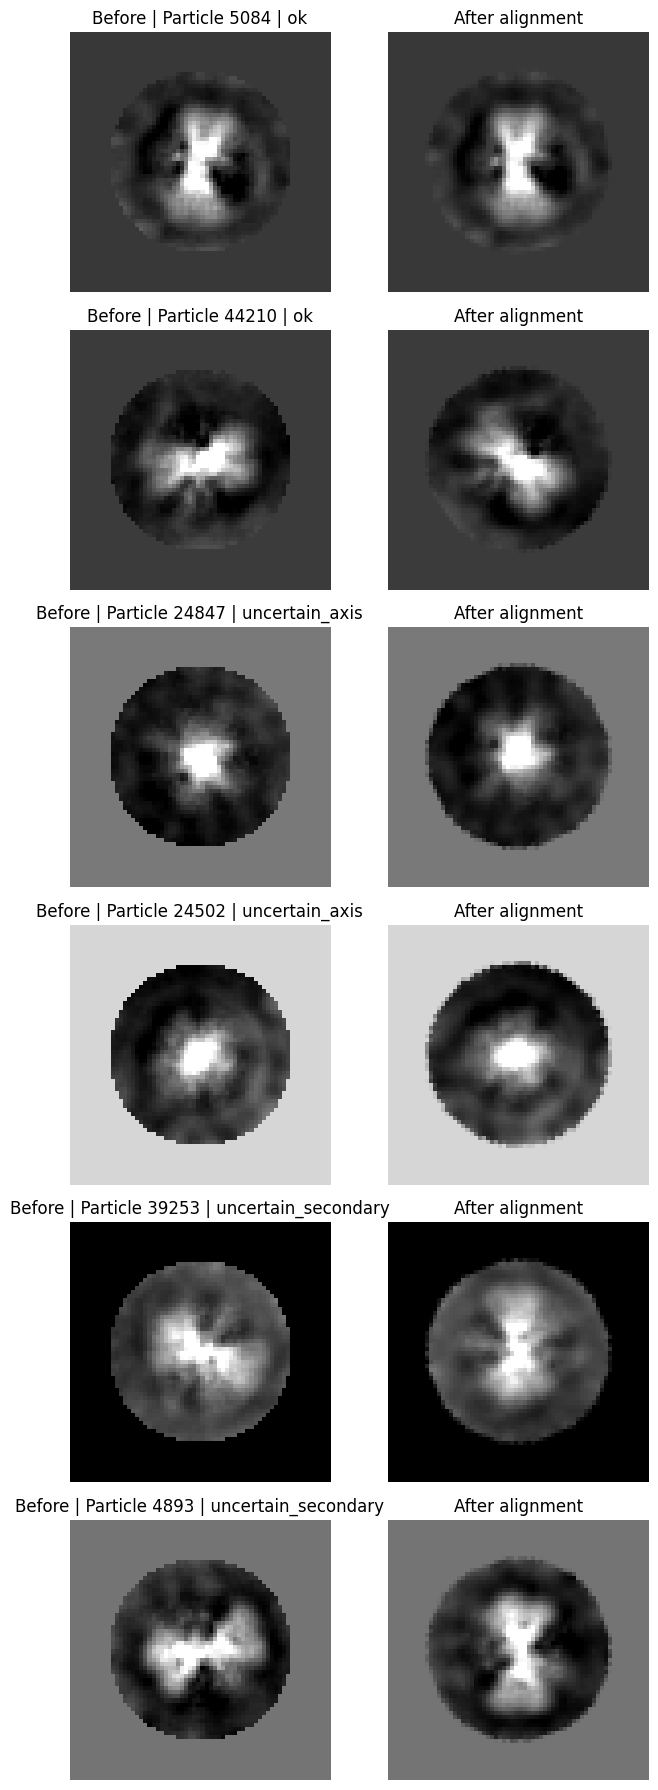

In [16]:
# ADDED: Visually inspect alignment results by status.

import numpy as np
import matplotlib.pyplot as plt
import particle_paired

# ADDED: Select two particles from each alignment status.
rng = np.random.default_rng(42)

selected_indices = []

for status in ("ok", "uncertain_axis", "uncertain_secondary"):
    candidates = np.flatnonzero(
        full_alignment_table["status"].to_numpy() == status
    )

    selected_indices.extend(
        rng.choice(candidates, size=2, replace=False).tolist()
    )

selected_indices = np.asarray(selected_indices, dtype=int)

# ADDED: Load only the selected images.
sample_images = np.asarray(
    seg_cropped["images"][selected_indices],
    dtype=np.float32,
)

sample_names = seg_cropped["image_names"][selected_indices]

# ORIGINAL: Reuse the saved alignment transformations.
aligned_samples, _ = particle_paired.apply_saved_alignment(
    images=sample_images,
    image_names=sample_names,
    directory=full_alignment_dir,
)

# ADDED: Show the original and aligned images side by side.
fig, axes = plt.subplots(6, 2, figsize=(7, 18))

for row, idx in enumerate(selected_indices):
    before = sample_images[row]
    after = aligned_samples[row]

    # ADDED: Use the same grayscale limits for each pair.
    vmin, vmax = np.percentile(before, [1, 99])

    axes[row, 0].imshow(
        before, cmap="gray", vmin=vmin, vmax=vmax
    )
    axes[row, 1].imshow(
        after, cmap="gray", vmin=vmin, vmax=vmax
    )

    status = full_alignment_table.iloc[idx]["status"]

    axes[row, 0].set_title(
        f"Before | Particle {idx + 1} | {status}"
    )
    axes[row, 1].set_title("After alignment")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

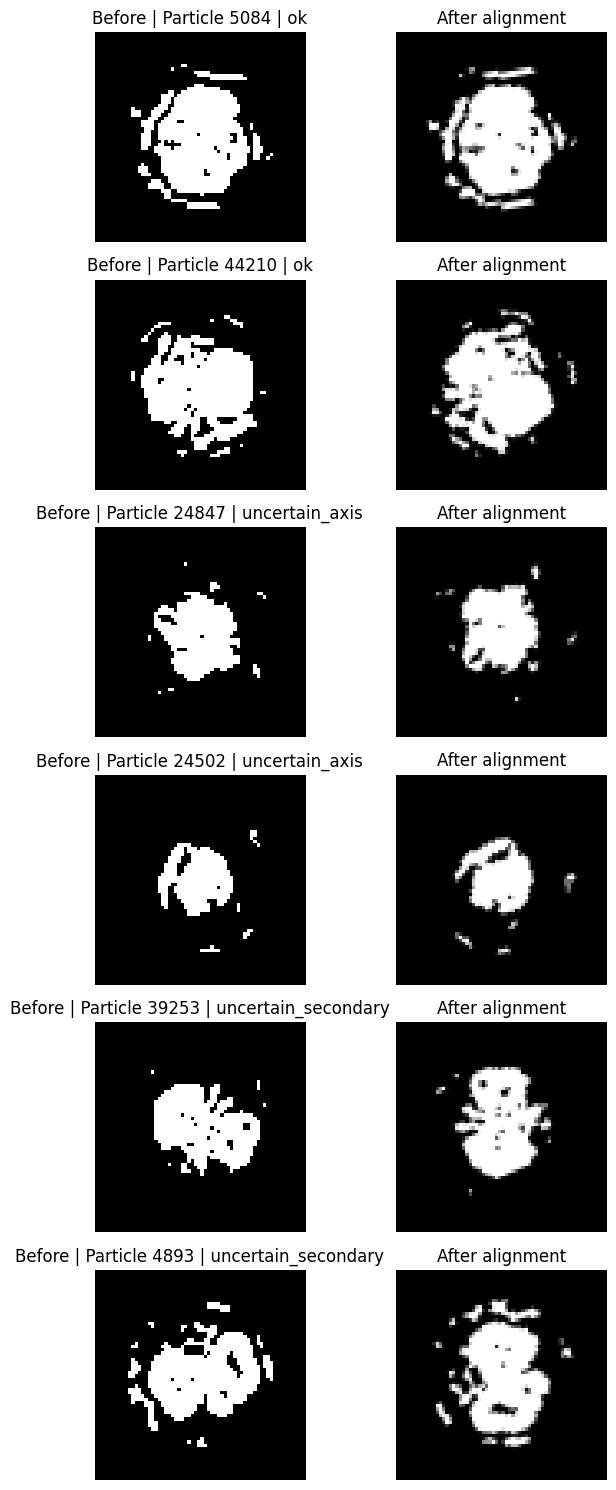

In [17]:
# ADDED: Inspect derivative maps before and after alignment.
# Reason: Alignment angles are estimated from derivative maps,
# so these are the correct images for evaluating that calculation.

import numpy as np
import matplotlib.pyplot as plt
import particle_paired

# ORIGINAL: Reuse the six particle indices selected in Step 8.13.
sample_derivatives = np.asarray(
    derivative_images[selected_indices],
    dtype=np.float32,
)

# ORIGINAL: Replay the saved transformations on derivative maps.
aligned_derivatives, _ = particle_paired.apply_saved_alignment(
    images=sample_derivatives,
    image_names=seg_cropped["image_names"][selected_indices],
    directory=full_alignment_dir,
)

# ADDED: Compare original and aligned derivative maps.
fig, axes = plt.subplots(6, 2, figsize=(7, 15))

for row, idx in enumerate(selected_indices):
    status = full_alignment_table.iloc[idx]["status"]

    axes[row, 0].imshow(
        sample_derivatives[row],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row, 1].imshow(
        aligned_derivatives[row],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row, 0].set_title(
        f"Before | Particle {idx + 1} | {status}"
    )
    axes[row, 1].set_title("After alignment")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

In [18]:

# ADDED: Define memory-efficient alignment for the full dataset.
#
# ORIGINAL: Reuse apply_saved_alignment() without changing
# the rotation, reflection, or interpolation calculations.
#
# This cell only defines the function.

from pathlib import Path
import numpy as np
import particle_paired

def apply_alignment_batched(
    images,
    image_names,
    transforms_directory,
    output_path,
    batch_size=32,
):

    # ADDED: Validate dataset dimensions and particle IDs.
    if images.ndim != 3:
        raise ValueError("Expected a 3D image stack.")

    if len(image_names) != len(images):
        raise ValueError("Image names do not match image rows.")

    output_path = Path(output_path)

    # ADDED: Do not overwrite an existing aligned dataset.
    if output_path.exists():
        raise FileExistsError(
            f"Aligned output already exists: {output_path}"
        )

    output_path.parent.mkdir(parents=True, exist_ok=True)

    # ADDED: Create one disk-backed output array.
    aligned_output = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.float32,
        shape=images.shape,
    )

    # ADDED: Process images in small batches.
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))

        # ADDED: Read only the current batch.
        batch_images = np.asarray(
            images[start:stop],
            dtype=np.float32,
        )

        batch_names = image_names[start:stop]

        # ORIGINAL: Apply the exact saved transformations.
        aligned_batch, _ = particle_paired.apply_saved_alignment(
            images=batch_images,
            image_names=batch_names,
            directory=transforms_directory,
        )

        # MODIFIED: Write aligned images directly to disk.
        aligned_output[start:stop] = aligned_batch

        # ADDED: Periodically flush the output.
        if stop % 1024 == 0 or stop == len(images):
            aligned_output.flush()

        if stop % 5000 < batch_size or stop == len(images):
            print(f"Aligned {stop:,} / {len(images):,} particles")

    aligned_output.flush()

    return aligned_output

print("Memory-efficient alignment function defined.")


Memory-efficient alignment function defined.


In [19]:
# ADDED: Compare batched alignment against the original method.

from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the verified cropping checkpoint.
test_images = seg_cropped["images"][:32]
test_names = seg_cropped["image_names"][:32]

# ADDED: Use a separate output file for this test.
test_output_path = (seg_project / "outputs" / "alignment_test_32" / "aligned_batched_test.npy")

# ADDED: Run alignment in batches of eight images.
batched_aligned = apply_alignment_batched(
    images=test_images,
    image_names=test_names,
    transforms_directory=full_alignment_dir,
    output_path=test_output_path,
    batch_size=8,
)

# ORIGINAL: Reuse the original alignment replay function.
original_aligned, _ = particle_paired.apply_saved_alignment(
    images=np.asarray(test_images, dtype=np.float32),
    image_names=test_names,
    directory=full_alignment_dir,
)

# ADDED: Compare the results pixel by pixel.
images_match = np.array_equal(
    batched_aligned,
    original_aligned,
)

assert images_match, "Batched alignment differs from original."

print("Batched alignment validation: PASSED")
print("Images compared:", len(test_images))
print("Output shape:", batched_aligned.shape)
print("Pixel-perfect match:", images_match)

Aligned 32 / 32 particles
Batched alignment validation: PASSED
Images compared: 32
Output shape: (32, 64, 64)
Pixel-perfect match: True


In [20]:
# ADDED: Align all 57,107 cropped CWF particle images.
# ORIGINAL: Reuse the validated apply_alignment_batched() function.
# MODIFIED: Process the complete dataset instead of 32 test images.
# Reason: Avoid allocating the full aligned stack in RAM.

from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the full alignment transformations from Step 8.11.
full_alignment_dir = (seg_project / "outputs" / "camille_cwf_full_alignment")

# ADDED: Choose a permanent output file.
aligned_original_path = (
    full_alignment_dir / "aligned_cropped_original.npy"
)

# ADDED: Apply the saved transformations in small batches.
aligned_original = apply_alignment_batched(
    images=seg_cropped["images"],
    image_names=seg_cropped["image_names"],
    transforms_directory=full_alignment_dir,
    output_path=aligned_original_path,
    batch_size=32,
)

# ADDED: Check the saved output dimensions.
assert aligned_original.shape == (57107, 64, 64)

print("\nFull CWF image alignment: COMPLETED")
print("Aligned images:", aligned_original.shape)
print("Saved file:", aligned_original_path)

Aligned 5,024 / 57,107 particles
Aligned 10,016 / 57,107 particles
Aligned 15,008 / 57,107 particles
Aligned 20,000 / 57,107 particles
Aligned 25,024 / 57,107 particles
Aligned 30,016 / 57,107 particles
Aligned 35,008 / 57,107 particles
Aligned 40,000 / 57,107 particles
Aligned 45,024 / 57,107 particles
Aligned 50,016 / 57,107 particles
Aligned 55,008 / 57,107 particles
Aligned 57,107 / 57,107 particles

Full CWF image alignment: COMPLETED
Aligned images: (57107, 64, 64)
Saved file: /Users/kr/ml4ls/outputs/camille_cwf_full_alignment/aligned_cropped_original.npy


In [21]:
# ADDED: Align all 57,107 cropped derivative maps.
# ORIGINAL: Reuse the saved alignment transformations.
# MODIFIED: Apply them to derivative maps rather than CWF images.
# Reason: Keep both image representations geometrically consistent.

from pathlib import Path
import numpy as np

# ADDED: Open the saved derivative maps without loading them all into RAM.
derivative_images = np.load(
    crop_checkpoint / "cropped_derivative.npy",
    mmap_mode="r",
)

# ADDED: Choose the permanent output file.
aligned_derivative_path = (
    full_alignment_dir / "aligned_cropped_derivative.npy"
)

# ORIGINAL: Reuse the validated memory-efficient alignment function.
aligned_derivative = apply_alignment_batched(
    images=derivative_images,
    image_names=seg_cropped["image_names"],
    transforms_directory=full_alignment_dir,
    output_path=aligned_derivative_path,
    batch_size=32,
)

# ADDED: Verify the output dimensions.
assert aligned_derivative.shape == (57107, 64, 64)

print("\nFull derivative alignment: COMPLETED")
print("Aligned derivative maps:", aligned_derivative.shape)
print("Saved file:", aligned_derivative_path)

Aligned 5,024 / 57,107 particles
Aligned 10,016 / 57,107 particles
Aligned 15,008 / 57,107 particles
Aligned 20,000 / 57,107 particles
Aligned 25,024 / 57,107 particles
Aligned 30,016 / 57,107 particles
Aligned 35,008 / 57,107 particles
Aligned 40,000 / 57,107 particles
Aligned 45,024 / 57,107 particles
Aligned 50,016 / 57,107 particles
Aligned 55,008 / 57,107 particles
Aligned 57,107 / 57,107 particles

Full derivative alignment: COMPLETED
Aligned derivative maps: (57107, 64, 64)
Saved file: /Users/kr/ml4ls/outputs/camille_cwf_full_alignment/aligned_cropped_derivative.npy


In [22]:

# ADDED: Register both completed aligned image stacks.
# Reason: Make batched alignment results compatible with
# the original Notebook 03 checkpoint loader.
# No images are copied or reprocessed.

import json
from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the completed alignment directory.
alignment_dir = (seg_project / "outputs" / "camille_cwf_full_alignment")

# ADDED: Verify the completed files.
for filename in (
    "alignment.csv",
    "transforms.npz",
    "aligned_cropped_original.npy",
    "aligned_cropped_derivative.npy",
):
    assert (alignment_dir / filename).is_file(), filename

# ADDED: Preserve the exact original CWF particle IDs.
names_path = alignment_dir / "image_names.npy"

if not names_path.exists():
    np.save(
        names_path,
        np.asarray(seg_cropped["image_names"], dtype=str),
        allow_pickle=False,
    )

# ADDED: Start with the existing crop settings and file references.
crop_settings = seg_cropped["settings"]

settings = {
    **crop_settings,
    "files": {
        **crop_settings["files"],
        "image_names": str(names_path.resolve()),
        "aligned_cropped_original": str(
            (alignment_dir / "aligned_cropped_original.npy").resolve()
        ),
        "aligned_cropped_derivative": str(
            (alignment_dir / "aligned_cropped_derivative.npy").resolve()
        ),
    },
    "blocks": {
        **crop_settings["blocks"],
        **{
            key: [{
                "name": key,
                "kind": "image",
                "start": 0,
                "stop": 4096,
            }]
            for key in (
                "aligned_cropped_original",
                "aligned_cropped_derivative",
            )
        },
    },
    "aligned_directory": str(alignment_dir.resolve()),
    "alignment_controls": alignment_controls,
}

# ADDED: Do not overwrite existing alignment settings.
settings_path = alignment_dir / "settings.json"

if settings_path.exists():
    raise FileExistsError(
        f"Alignment settings already exist: {settings_path}"
    )

settings_path.write_text(
    json.dumps(settings, indent=2) + "\n"
)

print("Alignment checkpoint registered successfully.")
print("Directory:", alignment_dir)
print("Particle IDs:", len(seg_cropped["image_names"]))
print("Metadata:", settings_path)


Alignment checkpoint registered successfully.
Directory: /Users/kr/ml4ls/outputs/camille_cwf_full_alignment
Particle IDs: 57107
Metadata: /Users/kr/ml4ls/outputs/camille_cwf_full_alignment/settings.json


In [23]:
# ADDED: Verify the complete alignment checkpoint.
# loader before continuing with feature extraction.
# Memory-safe: Image arrays remain memory-mapped.

from pathlib import Path
import numpy as np
from particle_paired import load_paired_dataset

# ORIGINAL: Reuse the saved alignment directory.
alignment_dir = (seg_project / "outputs" / "camille_cwf_full_alignment")

# ADDED: Load the aligned CWF image checkpoint.
seg_aligned = load_paired_dataset(
    root=seg_root,
    source="aligned_cropped_original",
    directory=alignment_dir,
)

# ADDED: Verify image dimensions and particle identities.
assert seg_aligned["images"].shape == (57107, 64, 64)
assert len(seg_aligned["image_names"]) == 57107

assert np.array_equal(
    seg_aligned["image_names"],
    seg_cropped["image_names"],
)

# ADDED: Verify the corresponding aligned derivative stack.
aligned_derivatives = np.load(
    alignment_dir / "aligned_cropped_derivative.npy",
    mmap_mode="r",
)

assert aligned_derivatives.shape == (57107, 64, 64)

print("Full alignment checkpoint: VERIFIED")
print("Aligned images:", seg_aligned["images"].shape)
print("Aligned derivative maps:", aligned_derivatives.shape)
print("Particle IDs:", len(seg_aligned["image_names"]))
print("Empty original derivative masks:",
      int(seg_aligned["empty_masks"].sum()))

Full alignment checkpoint: VERIFIED
Aligned images: (57107, 64, 64)
Aligned derivative maps: (57107, 64, 64)
Particle IDs: 57107
Empty original derivative masks: 0


## 3.3. Inspect the circle-cropped pair

Left: original CWF values within the circle. Right: thresholded derivative values (binary or magnitudes, as configured) within the same circle. Both are zero outside. Previews are also exported to the checkpoint folder.


In [ ]:
preview_pairs(seg_cropped, ["cropped_original", "cropped_derivative"], seg_preview_count, seg_export_dpi)


## 3.7. Align both channels using the cropped derivative

Estimate the intensity-weighted longest axis from `cropped_derivative`, rotate it vertically, then identify the strongest off-axis secondary lobe. Reflect vertically to put that lobe above the centroid and horizontally to put it to the right. The secondary bar need not be perpendicular. Reflections preserve the vertical main axis.

Replay the exact same rotation and flips on `cropped_original`. Save `aligned_cropped_original`, `aligned_cropped_derivative`, per-ID transforms, and ambiguity diagnostics. Rotation/reflections use the image center, bilinear interpolation, and zero padding. Near-symmetric or empty images have a deterministic fallback and are flagged; orientation is not uniquely identifiable for them.


With binary input, bilinear resampling produces fractional edge occupancy after rotation; these are not original edge strengths. The same recorded geometric operation is replayed on the original channel.

**ASPIRE options to explore later (not enabled here):** `BFTAverager2D` for fast rotational matching with a bounded translation search; `ReddyChatterjiAverager2D` for log-polar Fourier rotation estimation followed by translation; `RIRClass2D` for rotation-invariant neighbor discovery before class-local alignment. These align to references/neighbors rather than force an anatomical bar. A first benchmark could compare BFT rotation-only (`radius=0`) with a small shift radius (1–2 pixels), then replay transforms on the original channel. Reflection choices must be treated explicitly. See [ASPIRE classification documentation](https://computationalcryoem.github.io/ASPIRE-Python/aspire.classification.html).


In [ ]:
# Read the exact saved crop pair, not an independently recomputed derivative.
seg_crop_input = load_paired_dataset(seg_root, "cropped_original", seg_cropped["directory"])
seg_aligned = align_pairs(seg_root, seg_crop_input,
    exclusion=seg_alignment_secondary_exclusion, sector=seg_alignment_secondary_sector,
    min_axis_ratio=seg_alignment_min_axis_ratio, min_contrast=seg_alignment_secondary_contrast)
seg_alignment_table = pd.read_csv(seg_aligned["directory"] / "alignment.csv")
display(seg_alignment_table.groupby("status").size().rename("images").to_frame())
print(f"Saved paired alignment and replay transforms: {seg_aligned['directory']}")
preview_pairs(seg_aligned, ["cropped_derivative", "aligned_cropped_derivative", "aligned_cropped_original"], seg_preview_count, seg_export_dpi)
particle_paired.preview_alignment(seg_aligned, seg_preview_count, seg_export_dpi)


Section 3.7: Alignment checkpoint loaded successfully.
Aligned images: (57107, 64, 64)


,images
status,
ok,49414
uncertain_axis,4165
uncertain_secondary,3528


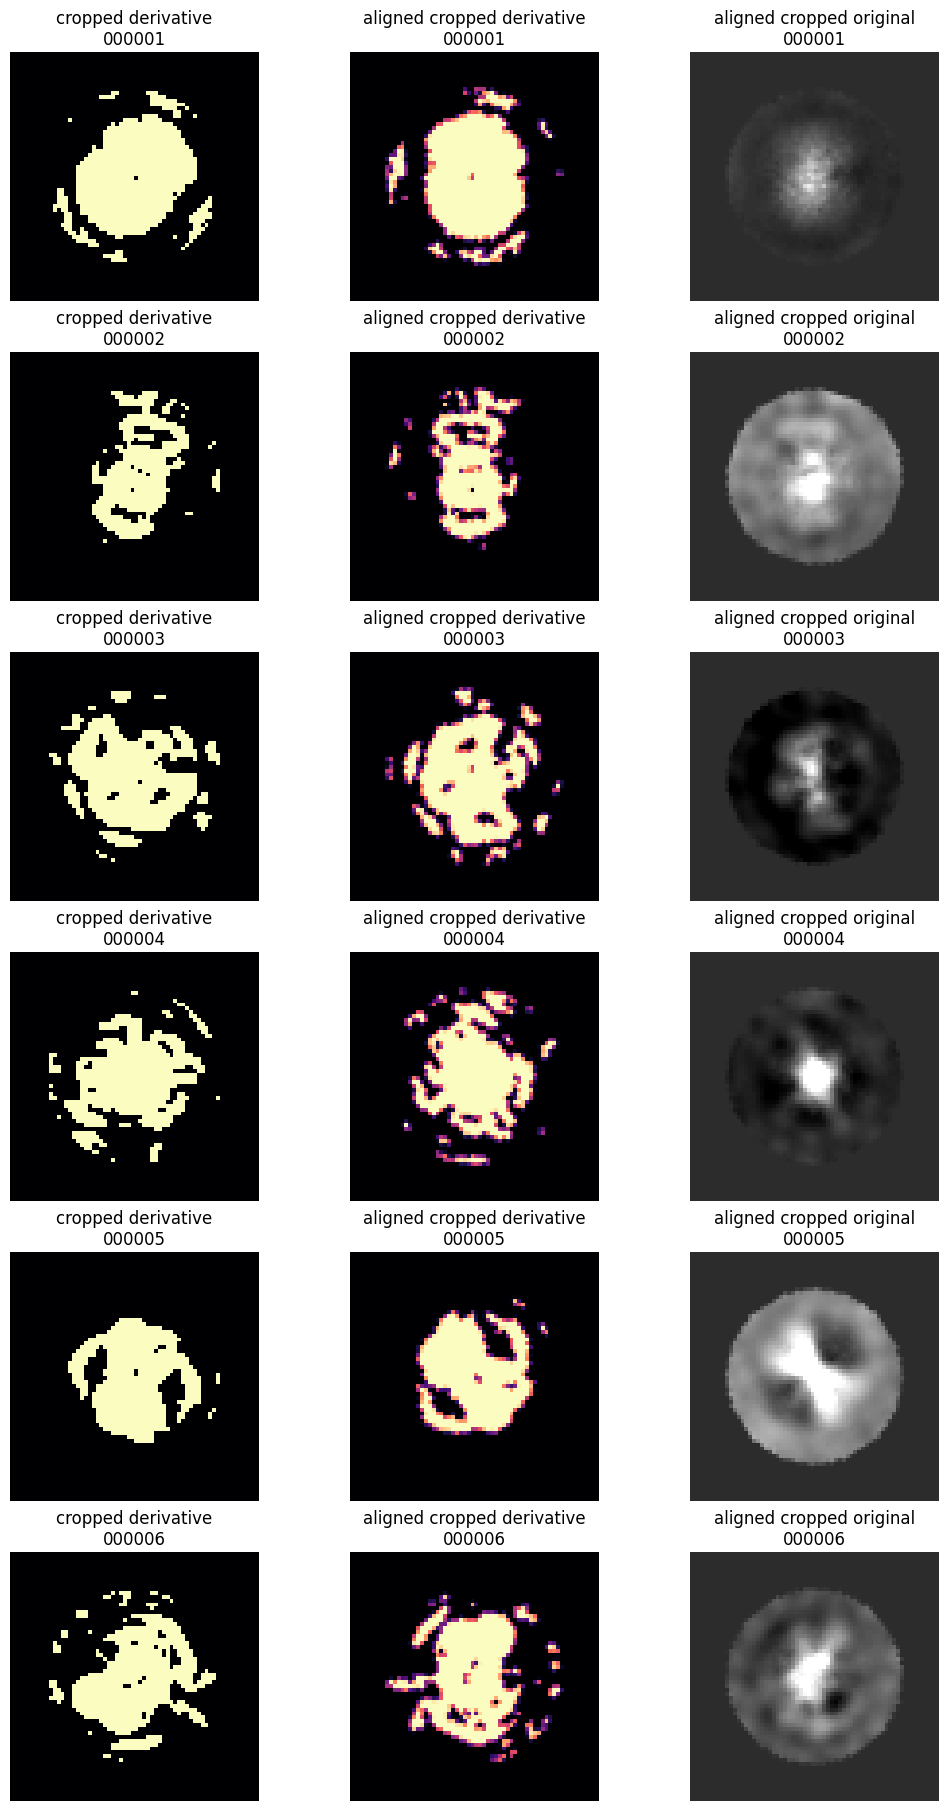

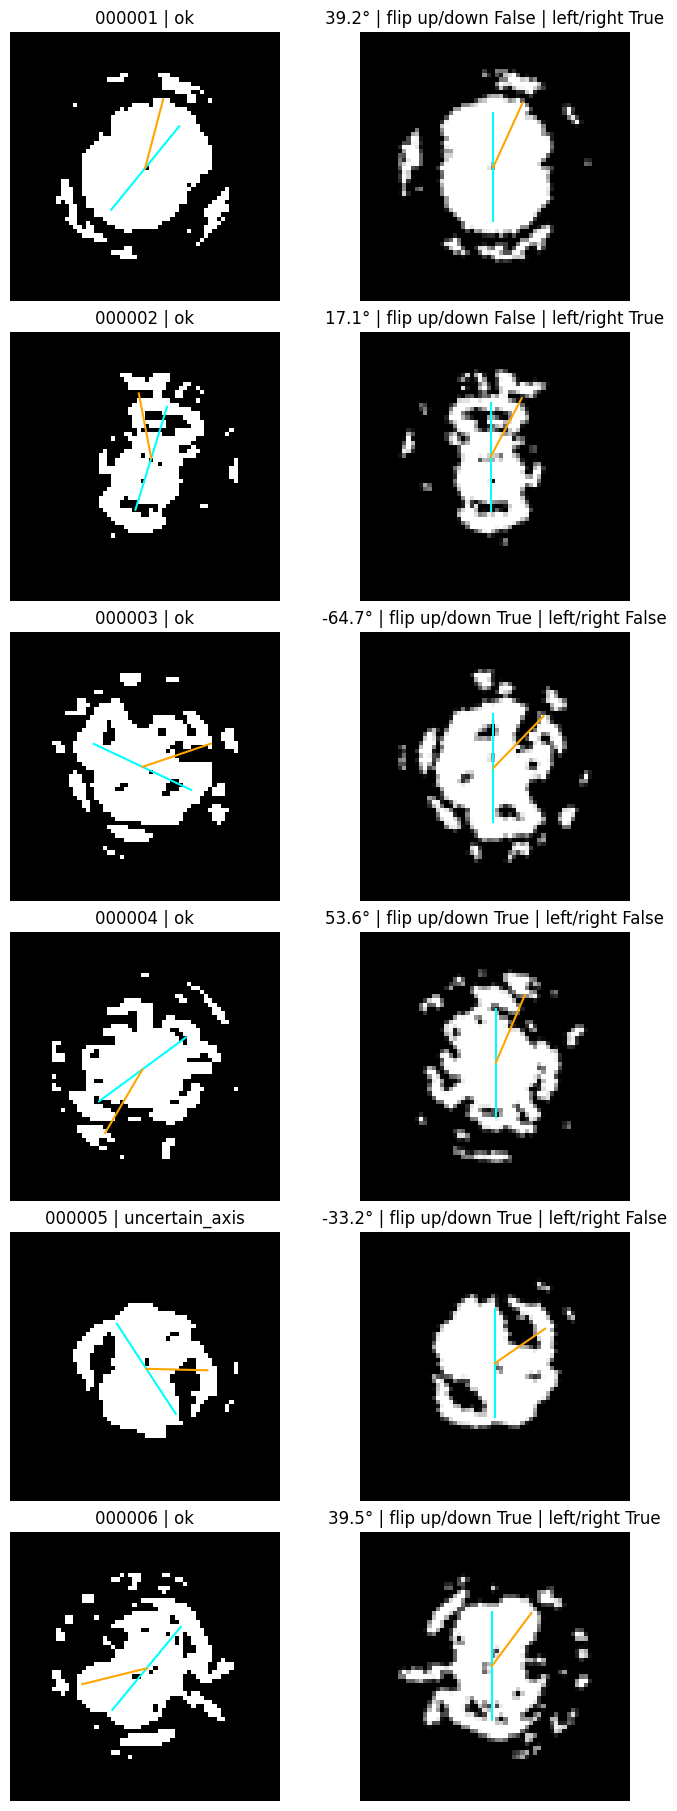

In [25]:
# ORIGINAL: Section 3.7 used align_pairs() to estimate and apply
# transformations to all images in memory.
#
# MODIFIED: Load the already-completed, memory-efficient alignment.
# Reason: Avoid repeating alignment of 57,107 particles.

from pathlib import Path
import pandas as pd
# ORIGINAL: Import the saved-dataset loader.
# MODIFIED: Also import the existing preview function.
from particle_paired import load_paired_dataset, preview_pairs

# ADDED: Locate the verified alignment checkpoint.
alignment_dir = (seg_project / "outputs" / "camille_cwf_full_alignment")

# MODIFIED: Load aligned particles instead of calling align_pairs().
seg_aligned = load_paired_dataset(
    root=seg_root,
    source="aligned_cropped_original",
    directory=alignment_dir,
)

# ADDED: Load the saved alignment quality measurements.
seg_alignment_table = pd.read_csv(
    alignment_dir / "alignment.csv"
)

# ADDED: Verify all particle IDs are represented.
assert len(seg_alignment_table) == len(seg_aligned["image_names"])

print("Section 3.7: Alignment checkpoint loaded successfully.")
print("Aligned images:", seg_aligned["images"].shape)

# ORIGINAL: Display the distribution of alignment quality.
display(
    seg_alignment_table.groupby("status")
    .size()
    .rename("images")
    .to_frame()
)

# ORIGINAL: Preview the saved image representations.
preview_pairs(
    seg_aligned,
    [
        "cropped_derivative",
        "aligned_cropped_derivative",
        "aligned_cropped_original",
    ],
    seg_preview_count,
    seg_export_dpi,
)

# ORIGINAL: Display the alignment diagnostics.
particle_paired.preview_alignment(
    seg_aligned,
    seg_preview_count,
    seg_export_dpi,
)

## 3.8. Aggregate aligned channels into radial bands × angular sectors

Use the existing crop circle; ignore everything outside it. Split it into `agg_n_radial_bands` equal-width rings, and each ring into `agg_n_sectors` clockwise sectors. Order bins from inner to outer ring, then clockwise within each ring, starting at `agg_start_angle_degrees`.

Each channel contains B intensity sums followed by B positive-pixel measurements, where B = bands × sectors. With `agg_count_mode="fraction"`, divide counts by each bin's pixel area; with `"count"`, retain counts. This is area correction, not normalization across the vector. `agg_positive_threshold` controls which pixels count, including interpolation values on rotated binary edges. Save total positive-pixel counts separately as diagnostics.

`aggregated_original` and `aggregated_derivative` remain the dataset names. Each now has 48 features with 3 rings × 8 sectors. Original-image positive pixels mean values above the chosen threshold, not a segmented particle area.


In [28]:
# ADDED: Validate batched radial aggregation against the original method.
# Reason: Confirm that splitting the images into batches
# preserves the original 48-feature calculations.
# Memory-safe: Uses only 32 aligned particle images.

import numpy as np
import particle_paired

# ORIGINAL: Reuse the existing aligned-image checkpoint.
test_images = np.asarray(
    seg_aligned["images"][:32],
    dtype=np.float32,
)

# ORIGINAL: Preserve all Section 3.8 aggregation settings.
aggregation_controls = {
    "n_sectors": agg_n_sectors,
    "n_radial_bands": agg_n_radial_bands,
    "radius_fraction": seg_growth_radius_fraction,
    "method": agg_method,
    "start_angle_degrees": agg_start_angle_degrees,
    "count_mode": agg_count_mode,
    "positive_threshold": agg_positive_threshold,
}

# ADDED: Calculate the original result using all 32 images together.
original_result = particle_paired.aggregate_polar(
    test_images,
    **aggregation_controls,
)

# MODIFIED: Calculate the same features in four batches of eight.
batched_vectors = []

for start in range(0, 32, 8):
    stop = min(start + 8, 32)

    batch_result = particle_paired.aggregate_polar(
        test_images[start:stop],
        **aggregation_controls,
    )

    batched_vectors.append(batch_result["vectors"])

# ADDED: Combine the small feature matrices.
batched_vectors = np.concatenate(batched_vectors, axis=0)

# ADDED: Verify the original and batched calculations match.
assert np.array_equal(
    original_result["vectors"],
    batched_vectors,
)

print("Batched radial aggregation: PASSED")
print("Particles:", len(batched_vectors))
print("Features per particle:", batched_vectors.shape[1])
print("Pixel-perfect feature match: True")

Batched radial aggregation: PASSED
Particles: 32
Features per particle: 48
Pixel-perfect feature match: True


In [29]:

# ORIGINAL: Section 3.8 used aggregate_pairs() on the full dataset.
# MODIFIED: Process aligned images in batches of 256.


from pathlib import Path
import numpy as np
import particle_paired

# ADDED: Use a dedicated output directory.
radial_dir = (seg_project / "outputs" / "camille_cwf_full_radial")

# ADDED: Avoid accidentally overwriting existing results.
if radial_dir.exists():
    raise FileExistsError(f"Directory already exists: {radial_dir}")

radial_dir.mkdir(parents=True)

# ORIGINAL: Keep the validated aggregation parameters.
aggregation_controls = {
    "n_sectors": agg_n_sectors,
    "n_radial_bands": agg_n_radial_bands,
    "radius_fraction": seg_growth_radius_fraction,
    "method": agg_method,
    "start_angle_degrees": agg_start_angle_degrees,
    "count_mode": agg_count_mode,
    "positive_threshold": agg_positive_threshold,
}

# ADDED: Determine the number of particles and features.
n_particles = len(seg_aligned["image_names"])
n_bins = agg_n_sectors * agg_n_radial_bands
n_features = 2 * n_bins
batch_size = 256

assert n_particles == 57107
assert n_features == 48

# MODIFIED: Process the two image channels separately.
for channel in ("original", "derivative"):

    # ADDED: Open aligned images without loading the full stack.
    images = np.load(
        alignment_dir / f"aligned_cropped_{channel}.npy",
        mmap_mode="r",
    )

    # ADDED: Create disk-backed feature output.
    vectors = np.lib.format.open_memmap(
        radial_dir / f"aggregated_{channel}.npy",
        mode="w+",
        dtype=np.float32,
        shape=(n_particles, n_features),
    )

    # ADDED: Preserve positive-pixel totals for compatibility.
    totals = np.lib.format.open_memmap(
        radial_dir / f"total_positive_pixels_{channel}.npy",
        mode="w+",
        dtype=np.float64,
        shape=(n_particles,),
    )

    for start in range(0, n_particles, batch_size):
        stop = min(start + batch_size, n_particles)

        # ORIGINAL: Use aggregate_polar() without changing its mathematics.
        result = particle_paired.aggregate_polar(
            images[start:stop],
            **aggregation_controls,
        )

        # MODIFIED: Save each batch directly to disk.
        vectors[start:stop] = result["vectors"]
        totals[start:stop] = result["total_positive_pixels"]

        # ADDED: Save spatial bin definitions from the first batch.
        if start == 0 and channel == "original":
            np.save(radial_dir / "sector_map.npy", result["sector_map"])
            np.save(radial_dir / "bin_pixel_counts.npy", result["pixel_counts"])

        if stop % 5120 < batch_size or stop == n_particles:
            print(f"{channel}: {stop:,} / {n_particles:,}")

    vectors.flush()
    totals.flush()

    # ADDED: Confirm the feature dimensions.
    assert vectors.shape == (57107, 48)

    print(f"{channel} radial features: SAVED")

print("\nFull radial feature extraction: COMPLETED")
print("Output directory:", radial_dir)



original: 5,120 / 57,107
original: 10,240 / 57,107
original: 15,360 / 57,107
original: 20,480 / 57,107
original: 25,600 / 57,107
original: 30,720 / 57,107
original: 35,840 / 57,107
original: 40,960 / 57,107
original: 46,080 / 57,107
original: 51,200 / 57,107
original: 56,320 / 57,107
original: 57,107 / 57,107
original radial features: SAVED
derivative: 5,120 / 57,107
derivative: 10,240 / 57,107
derivative: 15,360 / 57,107
derivative: 20,480 / 57,107
derivative: 25,600 / 57,107
derivative: 30,720 / 57,107
derivative: 35,840 / 57,107
derivative: 40,960 / 57,107
derivative: 46,080 / 57,107
derivative: 51,200 / 57,107
derivative: 56,320 / 57,107
derivative: 57,107 / 57,107
derivative radial features: SAVED

Full radial feature extraction: COMPLETED
Output directory: /Users/kr/ml4ls/outputs/camille_cwf_full_radial


In [30]:
# ADDED: Register completed radial features in the original checkpoint format.
# Reason: Allow downstream notebook stages to load the feature vectors.
# This cell does not recompute or copy the large image stacks.

import json
from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the completed radial feature directory.
radial_dir = (seg_project / "outputs" / "camille_cwf_full_radial")

# ADDED: Verify both 48-feature datasets exist.
for channel in ("original", "derivative"):
    feature_path = radial_dir / f"aggregated_{channel}.npy"

    assert feature_path.is_file()

    features = np.load(feature_path, mmap_mode="r")

    assert features.shape == (57107, 48)

# ADDED: Begin with the verified alignment checkpoint metadata.
settings = json.loads(
    (alignment_dir / "settings.json").read_text()
)

# ADDED: Register radial feature files and auxiliary arrays.
radial_keys = (
    "aggregated_original",
    "aggregated_derivative",
    "total_positive_pixels_original",
    "total_positive_pixels_derivative",
    "sector_map",
    "bin_pixel_counts",
)

for key in radial_keys:
    path = radial_dir / f"{key}.npy"
    assert path.is_file(), f"Missing radial output: {path}"
    settings["files"][key] = str(path.resolve())

# ADDED: Preserve the original sector-block organization.
n_bins = agg_n_sectors * agg_n_radial_bands

for channel in ("original", "derivative"):
    settings["blocks"][f"aggregated_{channel}"] = [
        {
            "name": f"{channel} {agg_method}",
            "kind": "sector",
            "start": 0,
            "stop": n_bins,
        },
        {
            "name": f"{channel} positive_pixel_{agg_count_mode}",
            "kind": "sector",
            "start": n_bins,
            "stop": 2 * n_bins,
        },
    ]

# ADDED: Record the exact aggregation settings.
settings.update({
    "n_sectors": agg_n_sectors,
    "n_radial_bands": agg_n_radial_bands,
    "n_bins": n_bins,
    "aggregation_method": agg_method,
    "start_angle_degrees": agg_start_angle_degrees,
    "normalization": "none",
    "count_mode": agg_count_mode,
    "positive_threshold": agg_positive_threshold,
    "bin_order": (
        "inner to outer equal-width rings, "
        "clockwise sectors within each ring"
    ),
})

# ADDED: Save the radial metadata without overwriting existing results.
settings_path = radial_dir / "settings.json"

if settings_path.exists():
    raise FileExistsError(
        f"Radial checkpoint already registered: {settings_path}"
    )

settings_path.write_text(json.dumps(settings, indent=2) + "\n")

print("Radial checkpoint registered successfully.")
print("Directory:", radial_dir)
print("Particles:", 57107)
print("Features per channel:", 48)

Radial checkpoint registered successfully.
Directory: /Users/kr/ml4ls/outputs/camille_cwf_full_radial
Particles: 57107
Features per channel: 48


In [31]:
# ADDED: Verify the saved radial feature checkpoint.
# Reason: Confirm compatibility with Notebook 03's original loader.


from pathlib import Path
import numpy as np
from particle_paired import load_paired_dataset

# ORIGINAL: Reuse the completed radial checkpoint.
radial_dir = (seg_project / "outputs" / "camille_cwf_full_radial")

# ADDED: Load original-image radial features.
seg_aggregated = load_paired_dataset(
    root=seg_root,
    source="aggregated_original",
    directory=radial_dir,
)

# ADDED: Load derivative-image radial features.
derivative_aggregated = load_paired_dataset(
    root=seg_root,
    source="aggregated_derivative",
    directory=radial_dir,
)

# ADDED: Verify the feature dimensions.
assert seg_aggregated["vectors"].shape == (57107, 48)
assert derivative_aggregated["vectors"].shape == (57107, 48)

# ADDED: Verify that particle identities and row order are preserved.
assert np.array_equal(
    seg_aggregated["image_names"],
    seg_aligned["image_names"],
)

assert np.array_equal(
    derivative_aggregated["image_names"],
    seg_aligned["image_names"],
)

# ADDED: Check a small sample for invalid feature values.
sample_rows = [0, 7138, 14276, 30000, 57106]

assert np.isfinite(
    seg_aggregated["vectors"][sample_rows]
).all()

assert np.isfinite(
    derivative_aggregated["vectors"][sample_rows]
).all()

print("Radial checkpoint verification: PASSED")
print("Original features:", seg_aggregated["vectors"].shape)
print("Derivative features:", derivative_aggregated["vectors"].shape)
print("Particle IDs:", len(seg_aggregated["image_names"]))
print("Feature values in sampled rows: finite")

Radial checkpoint verification: PASSED
Original features: (57107, 48)
Derivative features: (57107, 48)
Particle IDs: 57107
Feature values in sampled rows: finite


## 3.9. FFT of both aligned cropped channels

With `fft_remove_support_mean=True`, subtract each aligned image's mean **inside the saved crop circle** and set pixels outside that circle to zero. This removes the DC component without subtracting a constant from the zero background. The same geometric support is used for both channels, including pixels with zero edge value. No taper or per-image scale normalization is added. False retains the previous direct FFT behavior.

Save means for each image and channel, full complex spectra, and real `log1p(abs(spectrum))` descriptors as `fft_original` and `fft_derivative`, with zero frequency centered and orthonormal FFT scaling. The aligned image datasets remain unchanged; centering affects only the FFT branch.


In [33]:
# ORIGINAL: Section 3.9 uses fft_pairs() to extract Fourier features.
# MODIFIED: Run FFT processing separately from visualization.
# Reason: Verify the saved results before generating previews.

from particle_paired import fft_pairs, load_paired_dataset

# ORIGINAL: Load the completed alignment checkpoint.
seg_aligned_input = load_paired_dataset(
    seg_root,
    "aligned_cropped_original",
    seg_aligned["directory"],
)

# ORIGINAL: Reuse the existing batched FFT implementation.
seg_fft = fft_pairs(
    seg_root,
    seg_aligned_input,
    remove_support_mean=fft_remove_support_mean,
)

# ADDED: Verify that the FFT output was saved.
print("FFT processing: COMPLETED")
print("Checkpoint:", seg_fft["directory"])
print("FFT feature shape:", seg_fft["vectors"].shape)



FFT processing: COMPLETED
Checkpoint: /Users/kr/ml4ls/outputs/paired_9gcukaep
FFT feature shape: (57107, 4096)


## 3.10. Choose, balance, and concatenate feature blocks: `combined_cropped`

Remove/comment entries in `combined_feature_blocks` to select blocks and their order. `combined_scaling="block_variance"` centers each feature across the dataset, then divides each whole block by the square root of its total feature variance. Each nonconstant block then has unit total variance before applying its explicit weight. A weight w multiplies feature values, so its total variance becomes w². Constant blocks remain zero after centering. `"none"` preserves the previous uncentered/unscaled blocks (explicit weights still apply).

This balances block influence without scaling pixels independently or normalizing individual image vectors. Save the fitted feature means/gains, weights, raw and weighted variance totals, block boundaries, and shared IDs. Future images can reuse the saved transformation with `particle_paired.transform_combined`; do not fit a new scaling when projecting into an existing PCA model.

The eight selection keys are retained for compatibility. The `*_positive_pixel_count` slots contain counts **or occupancy fractions**, according to the saved aggregation settings. Each pixel/FFT block contains H×W features; each aggregation block contains B = rings × sectors. Selecting all eight gives `4*H*W + 4*B` (16,480 at 64×64, 3 rings, 8 sectors). PCA loading heatmaps show weights in the selected, scaled descriptor coordinates.

Rerun Sections 4–8 after changing preprocessing/selection/scaling. `combined_cropped` remains the input name; old checkpoints stay available. Compare clustering methods using the same exact saved PCA checkpoint.


In [35]:
# ADDED: Check that radial and FFT checkpoints use the same alignment.
# Reason: combine_pairs() requires matching alignment sources
# and exactly the same particle identities and ordering.
# This cell only checks metadata; it does not recompute features.

import numpy as np

radial_alignment = seg_aggregated["settings"]["aligned_directory"]
fft_alignment = seg_fft["settings"]["aligned_directory"]

assert radial_alignment == fft_alignment, (
    "Radial and FFT checkpoints reference different alignments."
)

assert np.array_equal(
    seg_aggregated["image_names"],
    seg_fft["image_names"],
), "Particle IDs or ordering differ."

assert seg_aggregated["vectors"].shape == (57107, 48)
assert seg_fft["vectors"].shape == (57107, 4096)

print("Checkpoint compatibility: PASSED")
print("Same alignment:", True)
print("Same particle IDs and ordering:", True)
print("Radial features:", seg_aggregated["vectors"].shape)
print("FFT features:", seg_fft["vectors"].shape)

Checkpoint compatibility: PASSED
Same alignment: True
Same particle IDs and ordering: True
Radial features: (57107, 48)
FFT features: (57107, 4096)


In [36]:
# MODIFIED: Disable full-dataset feature scaling.
# Reason: Prevent the held-out test particles from influencing
# feature normalization before cross-validation.
# ORIGINAL: combined_scaling = "block_variance"
combined_scaling = "none"
combined_block_weights = {
    "aligned_cropped_original": 1.0,
    "aligned_cropped_derivative": 1.0,
    "original_intensity_sum": 1.0,
    "original_positive_pixel_count": 1.0,
    "derivative_intensity_sum": 1.0,
    "derivative_positive_pixel_count": 1.0,
    "fft_original": 1.0,
    "fft_derivative": 1.0,
}  # Only selected blocks are used; weights multiply feature amplitudes.

# Choose any nonempty subset; list order is the concatenation order.
# MODIFIED: Use only the four radial feature blocks.
# ORIGINAL: The list contained eight blocks, including images and FFTs.
# Reason: Start with a smaller, 96-feature dataset for PCA/K-means.

combined_feature_blocks = [
    "original_intensity_sum",
    "original_positive_pixel_count",
    "derivative_intensity_sum",
    "derivative_positive_pixel_count",
]

# Reload so this cell also works in an already-running notebook kernel.
import importlib
import particle_aggregation
importlib.reload(particle_aggregation)
import particle_paired
importlib.reload(particle_paired)
seg_combined = particle_paired.combine_pairs(
    seg_root, seg_aggregated, seg_fft, selected_blocks=combined_feature_blocks,
    scaling=combined_scaling, block_weights=combined_block_weights,
)
print(f"Saved combined_cropped: {seg_combined['directory']}")
print(f"Feature matrix: {seg_combined['vectors'].shape}")
display(pd.DataFrame(seg_combined["settings"]["blocks"]["combined_cropped"]))


Saved combined_cropped: /Users/kr/ml4ls/outputs/paired_1yn3a_7i
Feature matrix: (57107, 96)


,name,kind,start,stop,selection_key,raw_total_variance,scale,weight,gain,constant,weighted_total_variance
0,original intensity_sum,sector,0,24,original_intensity_sum,55656.660925,1.0,1.0,1.0,False,55656.660925
1,original positive_pixel_fraction,sector,24,48,original_positive_pixel_count,3.337554,1.0,1.0,1.0,False,3.337554
2,derivative intensity_sum,sector,48,72,derivative_intensity_sum,3211.949077,1.0,1.0,1.0,False,3211.949077
3,derivative positive_pixel_fraction,sector,72,96,derivative_positive_pixel_count,0.578229,1.0,1.0,1.0,False,0.578229


In [37]:
# ADDED: Verify the final 96-feature checkpoint.
# Reason: Confirm feature dimensions, particle order,
# and consistency with the original radial features.

import numpy as np

# ADDED: Check the full combined feature matrix.
assert seg_combined["vectors"].shape == (57107, 96)

# ADDED: Confirm particle ordering is unchanged.
assert np.array_equal(
    seg_combined["image_names"],
    seg_aggregated["image_names"],
)

# ADDED: Confirm the combined features match the radial
# features before any model-specific scaling.
combined = seg_combined["vectors"]
radial_original = seg_aggregated["vectors"]
radial_derivative = derivative_aggregated["vectors"]

sample_rows = [0, 7138, 14276, 30000, 57106]

assert np.array_equal(
    combined[sample_rows, :48],
    radial_original[sample_rows],
)

assert np.array_equal(
    combined[sample_rows, 48:],
    radial_derivative[sample_rows],
)

assert np.isfinite(combined[sample_rows]).all()

print("Combined checkpoint verification: PASSED")
print("Feature shape:", combined.shape)
print("Particle order: MATCHED")
print("Radial features: MATCHED")
print("Sampled values: FINITE")

Combined checkpoint verification: PASSED
Feature shape: (57107, 96)
Particle order: MATCHED
Radial features: MATCHED
Sampled values: FINITE
